# Lesson 21: Sampled Current Voltammetry and Kinetics

If kinetics for an electron transfer reaction are excessively slow, then the Nernst equation struggles to assert itself at the electrode surface. In other words, the system is never at the thermodynamic equilibrium. This alters the behavior that we would expect to see.

Today's topics:
- Exploration of non-ideal situations
- Slow electron transfer kinetics
- Electrochemical irreversibility

**Reference:**
- Section 5.4 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
from echem import erf, erfc             # vectorised versions from scipy
echem.use_style()                       # course-wide graph formatting

# 1. Electrochemical Irreversibility in the Current Overpotential Equation

The current-overpotential equation was introduced in [Lesson 12](L12-Kinetics-II-Tafel.ipynb) and shown to simultaneously describe the mass transfer, thermodynamic, and kinetic characteristics of an electrochemical reaction. 

$
\large i = i_0 \left[ \frac{C_R(0,t)}{C_R^*} e^{(1-\alpha) F \eta / R T} -  \frac{C_O(0,t)}{C_O^*} e^{-\alpha F \eta / R T} \right]
$

It was subsequently shown in [Lesson 14](L14-Mass-Transfer-Limitations.ipynb) that pure mass-transfer limiting conditions provided a simpler mathematical representation of limiting currents, and that these equations could be combined with the current-overpotential equation to provide a more practical description of a system:

$
\large i = i_0 \left[ \left( 1-\frac{i}{i_{lim,a}}\right)e^{(1-\alpha) F \eta/RT} - \left(1-\frac{i}{i_{lim,c}}\right) e^{-\alpha F \eta/RT} \right]
$

This equation contains the terms $i_{lim,a}$ and $i_{lim,c}$, however, the values of which may not be explicitly known or experimentally distinguishable. Here, we will begin by further modifying the equation to make it both practical and applicable to real world measurements. The result will be an equation that provides direct insight into the role of electron transfer kinetics on observed behavior.

#### Modifying the Equation

We begin by considering $i_{lim}$, which was defined in [Lesson 14](L14-Mass-Transfer-Limitations.ipynb) as the difference between the anodic and cathodic limits:

$
\large i_{lim} = i_{lim,a}-i_{lim,c}
$

Note that the convention that anodic currents are positive was selected. The current-overpotential equation is divided by this value to yield $i/i_{lim}$, which we will define as our new y-axis value:

$
\large y = \frac{i}{i_{lim}} = \frac{i_0}{i_{lim}} \left[ \left( 1-\frac{i}{i_{lim,a}}\right)e^{(1-\alpha) F \eta/RT} - \left(1-\frac{i}{i_{lim,c}}\right) e^{-\alpha F \eta/RT} \right]
$

The $i_{lim,j}$ values need to be addressed next. If we assume that $m_O = m_R$, then $i_{lim,c}$ can be represented as some multiple of $i_{lim,a}$. We will call this multiple $m$:

$ 
\large i_{lim,a} = -m \cdot i_{lim,c}
$



This allows each component to be recast in terms of $i_{lim}$:

$ 
\large i_{lim,a} = \frac{i_{lim}}{1+1/m}
$

$ 
\large i_{lim,c} = -\frac{i_{lim}}{1+m}
$

Division of $i$ by each of these terms yields the $i/i_{lim,j}$ terms that are present in the initial equation yields:

$
\large \frac{i}{i_{lim,a}} = \frac{(1+1/m) \cdot i}{i_{lim}} = (1+1/m) \cdot y
$

$
\large \frac{i}{i_{lim,c}} = \frac{-(1+m) \cdot i}{i_{lim}} = -(1+m) \cdot y
$

Substitution into the current-overpotential equation, followed by expansion and rearrangement, yields:

$
\Large y = \frac{i}{i_{lim}} = \frac{e^{(1-\alpha)f \eta} - e^{-\alpha f \eta} }{i_{lim}/i_0 + (1+m)e^{-\alpha f \eta} + (1+1/m)e^{(1-\alpha) f \eta}}
$

In [2]:
@interact(i_lim_over_i0=widgets.FloatText(value=1e3, description=r'$i_{lim}/i_{0}$'),
          alpha=widgets.FloatSlider(value=0.5, min=0.01, max=0.99, step=0.01,
                                    description=r'$\alpha$'),
          c_o=widgets.FloatText(value=1e-3, step=0.001, description=r'$C_O$'),
          c_r=widgets.FloatText(value=1e-3, step=0.001, description=r'$C_R$'),
          eta_range=widgets.FloatRangeSlider(value=(-1.0, 1.0), min=-1.5, max=1.5,
                                             step=0.05, description=r'$\eta$'))
def plot_reversibility(i_lim_over_i0, alpha, c_o, c_r, eta_range):
    '''One knob, i_lim/i_0, carries you from reversible to irreversible.'''
    if c_o <= 0 or c_r <= 0:
        print('Both concentrations must be greater than zero: the equation contains 1/m.')
        return
    overpotential = np.linspace(eta_range[0], eta_range[1], 501)
    current = echem.current_overpotential(overpotential, i_lim_over_i0,
                                          alpha=alpha, conc_ratio=c_r/c_o)
    fig = plt.figure()
    ax = plt.subplot()
    ax.set_xlabel(r'$\eta$ / V')
    ax.set_ylabel(r'$i / i_{lim}$  (anodic positive)')
    ax.plot(overpotential, current)

interactive(children=(FloatText(value=1000.0, description='$i_{lim}/i_{0}$'), FloatSlider(value=0.5, descripti…

<div class="alert alert-block alert-info">
<b>Activity:</b> Articulate the physical meaning of each term used in the modified equation above. 
</div>

In [Lesson 12](L12-Kinetics-II-Tafel.ipynb) we established that in the conditions that:

$
\large C_O(0,t) = C_O^*
$

$
\large C_R(0,t)=C_R^*
$

We could observe "Tafel" behavior:

$
\large i = i_0 \left[e^{(1-\alpha)f \eta}  - e^{-\alpha f \eta}\right]
$

We plotted this equation with varied $i_0$ to see the impact of electrochemical irreversibility. Let us now revisit the figure:

In [3]:
@interact(scale=widgets.RadioButtons(options=[1e-5, 1e-8, 1e-11], description='y scale'))
def plot_exchange_current_scale(scale):
    '''Rescaling the y axis just slides the curves: the shape is set by i_0 alone.'''
    exchange_currents = [1e-9, 1e-6, 1e-3]      # A
    alpha = 0.5
    overpotential = np.linspace(-0.5, 0.5, 100)

    fig = plt.figure()
    ax = plt.subplot(111)
    for i_0 in exchange_currents:
        ax.plot(overpotential, echem.butler_volmer_from_i0(overpotential, i_0, alpha),
                label=i_0)
    ax.set_ylim(-scale, scale)
    ax.set_xlabel(r'$\eta$ / V')
    ax.set_ylabel(r'$i$ /A  (anodic positive)')
    ax.legend(loc=(0.03, 0.6), fontsize=8, title=r'$i_0$')

interactive(children=(RadioButtons(description='y scale', options=(1e-05, 1e-08, 1e-11), value=1e-05), Output(…

The $i_0$ values in the figure above vary by a factor of 1000. Scaling of the y-axis results in a simple shifting of the data.

<div class="alert alert-block alert-info">
<b>Discussion:</b> Consider the two figures above. What factors lead to <b>electrochemical irreversibility</b>? What insights can we draw out of this?
</div>

Electrochemical reversibility depends upon 
- ...

Lets have a look at the first figure from today from a different perspective:

In [4]:
@interact(i_lim_over_i0=widgets.Text(value='1000, 1000, 1000', description=r'$i_{lim}/i_0$'),
          alphas=widgets.Text(value='0.3, 0.5, 0.7', description=r'$\alpha$'),
          c_o=widgets.FloatText(value=1e-3, step=0.001, description=r'$C_O$'),
          c_r=widgets.FloatText(value=1e-3, step=0.001, description=r'$C_R$'),
          eta_range=widgets.FloatRangeSlider(value=(-1.0, 1.0), min=-1.5, max=1.5,
                                             step=0.05, description=r'$\eta$'))
def plot_alpha_comparison(i_lim_over_i0, alphas, c_o, c_r, eta_range):
    '''Compare several (alpha, i_lim/i_0) pairs on one set of axes.'''
    if c_o <= 0 or c_r <= 0:
        print('Both concentrations must be greater than zero: the equation contains 1/m.')
        return
    try:
        alphas = echem.parse_numbers(alphas, name='alpha')
        ratios = echem.parse_numbers(i_lim_over_i0, expected=alphas.size,
                                     name='i_lim/i_0')
    except ValueError as problem:
        print(problem)
        return

    overpotential = np.linspace(eta_range[0], eta_range[1], 501)
    fig = plt.figure()
    ax = plt.subplot()
    ax.set_xlabel(r'$\eta$ / V')
    ax.set_ylabel(r'$i / i_{lim}$  (anodic positive)')
    for alpha, ratio in zip(alphas, ratios):
        ax.plot(overpotential,
                echem.current_overpotential(overpotential, ratio,
                                            alpha=alpha, conc_ratio=c_r/c_o),
                label=rf'$\alpha={alpha}, i_{{lim}}/i_0={ratio:g}$')
    ax.legend(loc=(0.05, 0.75), fontsize=6)

interactive(children=(Text(value='1000, 1000, 1000', description='$i_{lim}/i_0$'), Text(value='0.3, 0.5, 0.7',…

It is worth the effort to remember the specific impact that each parameter has on the structure of your data:
- $i_0$: the rate at which the reaction occurs when no net current flows. 
- $\alpha$: the symmetry of the potential energy surfaces. A higher value favors cathodic reactions (remember, echem was developed on reductions!) while a lower value favors anodic reactions
- $i_{lim}$: the maximum rate that a solvated species can be transported to the electrode surface
- $i_{lim}/i_0$: the relative balance between mass transfer limitations and kinetic limitations in the system. This is the parameter that dictates whether you *observe* electrochemical irreversibility.

This information provides a more nuanced perspective on the "Tafel" behavior introduced in [Lesson 12](L12-Kinetics-II-Tafel.ipynb). It necessitates **slow kinetics** and **fast mass transfer**...HOWEVER, these are **relative definitions**. If a reaction is *chemically reversible*, it is theoretically possible to perform experiments in which it will be *electrochemically reversible*, and *electrochemically irreversible*.

<div class="alert alert-block alert-success">
<b>Electron Transfer Kinetics:</b> It is important to note that the electron transfer kinetics for an electrochemically reversible reaction cannot be measured by voltammetry.
</div>

# 2. Quasireversible Reactions

We have now seen the two extremes of behavior: 
- electrochemical reversibility: behavior follows that dictated by the Nernst equation
- electrochemical irreversibility: behavior deviates from the Nernst equation

Manipulation of the diagram above should convince you that there is no sharp transition between reversible and irreversible behavior. Rather, there is an extended period where the "edges" of the curve begin to soften and distort without having much impact on the overall behavior. This observation transfers to many of the experimental techniques that we will cover: the observed behavior is deceptively close to being electrochemically reversible, but is not. This region of behavior is referred to as **quasireversibility**.

The term **quasireversible** is often thrown around very casually, making it a frustrating term to really understand. There is, however, a very clear definition that is based on math. To get there, we will consider our standard generalized reaction at a macrodisk electrode once more. This reaction will now be envisioned to be under **kinetic control**. That is to say, the Nernst equation fails to describe what is happening at the surface of the electrode.

#### Establishing a Model

The electrochemical reaction still requires mass transfer through solution, which we will assume to be via semi-infinite diffusion. The boundary conditions therefore begin the same as in [Lesson 20](L20-SampledCurrent.ipynb):

$\large \frac{\delta C_O(x,t)}{\delta t} = D_O \frac{\delta^2 C_O(x,t)}{\delta x^2}$

$\large \frac{\delta C_R(x,t)}{\delta t} = D_R \frac{\delta^2 C_R(x,t)}{\delta x^2}$

$\large C_O(x,0)=C_O^*$

$\large C_R(x,0)=0$

$\large \lim_{x \to \infty} C_O(x,t) = C_O^*$

$\large \lim_{x \to \infty} C_R(x,t) = 0$

$ \large D_O\left(\frac{\delta C_O(x,t)}{\delta x}\right)_{x=0} + D_R \left(\frac{\delta C_R(x,t)}{\delta x} \right)_{x=0} = 0 $

The final condition, however, must now change because the Nernst equation has become inaccurate. Being under kinetic control, we use the equation for electron transfer kinetics. The rate of mass transfer must equal the rate of electron transfer while under kinetic control, or the solution would spontaneously concentrate:

$\large \frac{i}{FA} = k_cC_O(0,t) - k_aC_R(0,t) = D_O \left( \frac{\delta C_O(x,t)}{\delta x}\right)_{x=0}$

Remember that $k_c$ and $k_a$ are dependent on overpotential, as discussed in [Lesson 11](L11-Kinetics-I-ButlerVolmer.ipynb):

$ \large k_c = k^0e^{-\alpha f \eta}$

$ \large k_a = k^0e^{(1-\alpha) f \eta}$

<div class="alert alert-block alert-warning">
<b>Project Idea:</b> An introduction to Laplace transforms and their utility in electrochemistry would be an excellent presentation topic for a mathematically inclined individual!
</div>

Laplace transforms using the new boundary condition yield:

$
\large i(t) = FA(k_aC_R^* - k_cC_O^*)e^{H^2t}erfc(H\sqrt{t})
$

Substituting the Butler-Volmer expressions for $k_c$ and $k_a$, this can also be written as:

$
\large i(t) = i_0\left[ e^{(1-\alpha) f \eta} - e^{-\alpha f \eta} \right]e^{H^2 t}erfc(H\sqrt{t})
$

And for **small overpotentials** (<50 mV) it can be simplified to:

$
\large i(t) = \frac{F i_0 \eta}{RT} e^{H^2 t}erfc(H\sqrt{t})
$

For all equations:

$
\large H = \frac{k_c}{\sqrt{D_O}}+\frac{k_a}{\sqrt{D_R}}
$

And the complementary error function is:

$
\large erfc(x) = 1-erf(x)
$

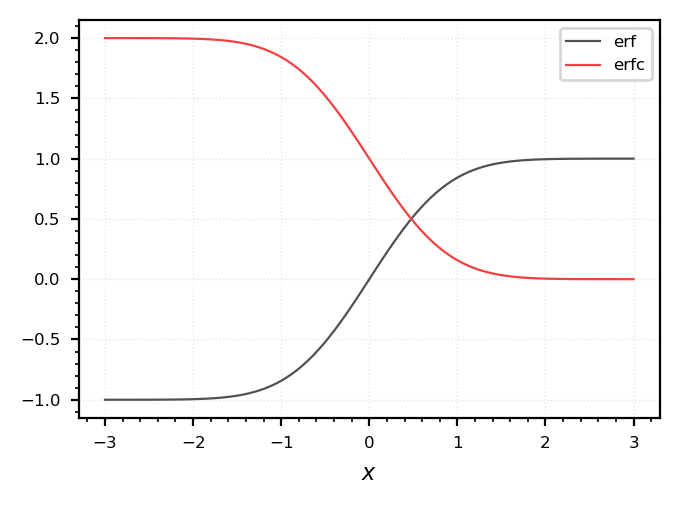

In [5]:
# erf and erfc, both vectorised.  erfc(x) = 1 - erf(x).
x = np.linspace(-3, 3, 100)

fig = plt.figure()
ax = plt.subplot()
ax.plot(x, erf(x), label='erf')
ax.plot(x, erfc(x), label='erfc')
ax.set_xlabel(r'$x$')
ax.legend(fontsize=6)

The equations above are the embodiment of the electrochemical irreversibility that we have observed. Consider that we used $i_{lim}/i_0$ as a parameter in our above figures, where irreversibility became prominent with $i_{lim} >> i_0$. The $H\sqrt{t}$ term is small when $i_0 < i_{lim}$, which enables the exponential term to be approximated as:

$
\large e^{H^2t} erfc(H\sqrt{t}) \approx 1-\frac{2H\sqrt{t}}{\sqrt{\pi}}
$

Such that:

$
\large i(t) = \frac{F i_0 \eta}{RT}\left[1-\frac{2H\sqrt{t}}{\sqrt{\pi}}\right]
$

We can see here that when $D_j$ values are large compared to $k_j$, $H$ becomes small and the second component becomes negligible. This is the condition of electrochemical irreversibility. As $k_j$ increases relative to $D_j$, however, this second term must be considered.

# 3. Generalized Behavior

Following this line of development one can generalize the behavior for sampled current voltammetry such that it spans all three behavior conditions. Remembering the dimensionless parameters and the diffusion-limited equation:

$
\large \xi = \sqrt{\frac{D_O}{D_R}}
$

$
\large \theta = \frac{C_O}{C_R} = e^{nF(E-E^{0'})/RT}
$

$
\large i_d(t) = \frac{nFA\sqrt{D_j}C_j^*}{\sqrt{\pi t}}
$

We can generalize:

$
\large i = \frac{i_d}{1+\xi \theta}F_1(\lambda)
$

Where:

$
\large F_1(\lambda) = \sqrt{\pi} \lambda e^{\lambda^2} erfc(H\sqrt{t})
$

And:

$
\large \lambda = H\sqrt{t} = \frac{k_f\sqrt{t}}{\sqrt{D}}(1 + \xi \theta)
$

In [6]:
@interact(t=widgets.FloatText(value=1.0, description=r'$t$'),
          co=widgets.FloatText(value=1e-5, description=r'$C_O^*$'),
          cr=widgets.FloatText(value=1e-5, description=r'$C_R^*$'),
          do=widgets.FloatText(value=1e-5, description=r'$D_O$'),
          dr=widgets.FloatText(value=1e-5, description=r'$D_R$'),
          k0_list=widgets.Text(value='0.001, 0.00001', description=r'$k^0$ (csv)'),
          alpha=widgets.FloatSlider(value=0.5, min=0.1, max=0.9, description=r'$\alpha$'))
def plot_quasireversible(t, co, cr, do, dr, alpha, k0_list):
    '''Slow kinetics drag the wave out.  Watch what k0 does to its position and width.

    The maths uses erfcx, the scaled complementary error function, because
    exp(H^2 t) erfc(H sqrt(t)) overflows to inf*0 = NaN if computed directly.
    '''
    if min(t, co, cr, do, dr) <= 0:
        print('t, the concentrations and the diffusion coefficients must all be positive.')
        return
    try:
        k0_values = echem.parse_numbers(k0_list, name='k0')
    except ValueError as problem:
        print(problem)
        return

    overpotential = np.linspace(-0.5, 0.5, 200)
    fig = plt.figure()
    ax = plt.subplot()
    ax.set_xlabel(r'$\eta$ / V')
    ax.set_ylabel(r'$i/i_{lim}$  (anodic positive)')

    for k0 in k0_values:
        current = echem.quasireversible_step_current(overpotential, k0, co, cr,
                                                     do, dr, t, alpha=alpha)
        ax.plot(overpotential, current/(current.max() - current.min()),
                label=rf'$k^0$={k0:.2e}')
    ax.legend(loc=(0.1, 0.55), fontsize=6)

interactive(children=(FloatText(value=1.0, description='$t$'), FloatText(value=1e-05, description='$C_O^*$'), …

This form of the equation allows us to understand the **degrees of electrochemical reversibility**. Under the special conditions of $E=E^{0'}$ and $\theta = 1$ (see [Lesson 12](L12-Kinetics-II-Tafel.ipynb)) we can define a dimensionless term that describes the inherent relationship between the **standard rate constant** and diffusion:

$
\large \lambda^0 = \frac{(1 + \xi) k^0 \sqrt{t}}{\sqrt{D_j}}
$

#### Reversible:
- Sampled current $i(\tau)/i_d(\tau)$ behavior is dictated by the Nernst equation
- Kinetic effects are not measurable
- $\lambda^0 > 2$

#### Quasireversible
- $i(\tau)/i_d(\tau)$ deviates from the Nernst equation
- Kinetic effects are barely measurable
- $10^{-2\alpha} < \lambda^0 < 2$

#### Irreversible
- $i(\tau)/i_d(\tau)$ deviates from the Nernst equation
- either $k_a$ or $k_c$ are $\approx 0$ for all voltages where a non-zero current flows
- $\lambda^0 < 10^{-2\alpha}$

<div class="alert alert-block alert-info">
<b>Activity:</b> Two systems give identical drawn-out waves. One has genuinely slow kinetics; the other has fast kinetics but a badly compensated cell.
<br>
Describe one experiment that would tell them apart, and state what result would point at each.
</div>

- Experiment: ANSWER
- Result indicating slow kinetics: ANSWER
- Result indicating uncompensated resistance: ANSWER